# NaiNUQ two-year emulator forecast (local, MPS/CPU)

This notebook runs the pre-trained **NaiNUQ 6 h emulator** (sub-surface ocean currents used as
forcings) over the **full two-year test set (2019 and 2020)** available on Zenodo, the same way the
headless script `run_local.py` does. For every forecast it computes the RMSE and bias against NANUQ
as a function of lead time, as well as the persistence RMSE.

It differs from `notebooks/nainuq_demo_6h_rmse.ipynb` in three ways:

1. **Full two years** of test data (2019 + 2020, 1440 forecasts at `frequency = 12 h`), not a 2019 subset.
2. **NN inference timing** is measured and reported (time per forward pass and per forecast cycle).
3. **No prediction outputs are saved** — only the aggregate RMSE / bias / persistence arrays and timing
   statistics are kept in memory (and optionally saved as small `.npy` metric files).

The repository code (`UNetModel`, `Test.apply_emulator`) is reused unchanged, so the numbers are
computed exactly like in `run_local.py` / `inference/test.py`.


## Reproducibility & environment

This notebook was run with the `nainuq_arm` conda environment (see the README section *Environment*).
Because the full two-year dataset (~19.5 GB if loaded at once) exceeds a typical laptop RAM, this
notebook **streams the TFRecords**: it reads the hourly records once, keeps only a sliding window of
the current forecast in memory, and discards it after each cycle. This reproduces exactly the same
forecasts as `run_local.py` while staying under a few hundred MB of RAM.

**Prerequisites** (see the README):

- conda env `nainuq_arm` (Apple Silicon / MPS) or `nainuq` (CUDA): `conda env create -f nainuq.yml`
- weights in `weights/last.ckpt` (download from Hugging Face, see README)
- two-year test data in `data/data_20*.tfrecords.*` + normalisation constants `data/sea_ice_*.npy`
- this notebook placed in `<repo>/notebooks/`


In [1]:
import os, sys, io, argparse, contextlib, time
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
from pathlib import Path
from unittest import mock

import numpy as np
import torch
import tensorflow as tf
try:
    tf.config.set_visible_devices([], "GPU")   # TF only reads TFRecords; keep the GPU for PyTorch
except Exception:
    pass
import matplotlib.pyplot as plt
from tqdm.auto import trange

# ------------------------------------------------------------------ paths
REPO_ROOT   = Path("..").resolve()        # notebook lives in <repo>/notebooks/
WEIGHTS_DIR = REPO_ROOT / "weights"
DATA_DIR    = REPO_ROOT / "data"
OUT_DIR     = REPO_ROOT / "notebooks" / "two_year_output"
OUT_DIR.mkdir(exist_ok=True)

# ------------------------------------------------------------------ emulator configuration
# (6 h, sub-surface ocean as forcings: identical to run_local.py)
VARIABLES             = ["sit", "sic", "siu", "siv", "snt"]
TIMESTEP              = 6       # hours per emulator step
NN_SIZE               = 32
USE_OCEAN_AS_FORCINGS = True
POST_PROCESSING       = True

# ------------------------------------------------------------------ forecast configuration
K         = 41     # emulator steps per forecast (step 40 = 10 days)
FREQUENCY = 12     # hours between two forecast start times
N_CYCLE   = 1440   # forecasts over the two years (2019 + 2020), 12 h apart

# ------------------------------------------------------------------ device (MPS on Apple Silicon)
def get_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

device = get_device()
print(f"device: {device} | torch {torch.__version__} | tf {tf.__version__}")


device: mps | torch 2.14.1 | tf 2.16.2


## 1. Locate code, weights, data and normalisation constants

In [2]:
CODE_DIR = REPO_ROOT / "nainuq"             # contains layers/, inference/, datasets/
assert (CODE_DIR / "layers" / "full_UNet.py").exists(), f"Repo code not found in {CODE_DIR}"
MASK_PATH = CODE_DIR / "layers" / "mask2_nanuk1.npy"

# weights (prefer last.ckpt, as in the slurm script)
ckpts = sorted(WEIGHTS_DIR.rglob("*.ckpt")) + sorted(WEIGHTS_DIR.rglob("*.pt"))
assert ckpts, f"No checkpoint found under {WEIGHTS_DIR}"
CKPT_PATH = ([c for c in ckpts if c.name == "last.ckpt"] or ckpts)[0]

# data: the folder holding the normalisation constants is the "data_path" expected by Test
norm_files = sorted(DATA_DIR.rglob("sea_ice_mean_input.npy"))
assert norm_files, f"sea_ice_mean_input.npy not found under {DATA_DIR}"
DATA_PATH = str(norm_files[0].parent) + "/"
TFRECORDS = sorted(Path(DATA_PATH).rglob("data_20*.tfrecords.*"))
assert TFRECORDS, f"No data_20*.tfrecords.* found under {DATA_PATH}"

print("checkpoint :", CKPT_PATH)
print("data path  :", DATA_PATH)
print("tfrecords  :", len(TFRECORDS), "shard(s)")
print("mask       :", MASK_PATH)


checkpoint : /Users/durandc/Desktop/NaiNUQ/weights/last.ckpt
data path  : /Users/durandc/Desktop/NaiNUQ/data/
tfrecords  : 88 shard(s)
mask       : /Users/durandc/Desktop/NaiNUQ/nainuq/layers/mask2_nanuk1.npy


## 2. Import the repository code

In [3]:
sys.path.insert(0, str(CODE_DIR))
from layers.full_UNet import UNetModel
from inference.test_utils import Test

@contextlib.contextmanager
def repo_quirks():
    real_load = np.load
    def load(path, *a, **k):
        if str(path).endswith("mask2_nanuk1.npy"):
            path = MASK_PATH
        return real_load(path, *a, **k)
    with mock.patch.object(np, "load", load), \
         mock.patch.object(np, "save", lambda *a, **k: None), \
         contextlib.redirect_stdout(io.StringIO()):
        yield


## 3. Load the model and measure NN inference speed

In [4]:
N_OCEAN = 5 if USE_OCEAN_AS_FORCINGS else 0
N_UNDER = 0
IN_CH   = 7 + N_UNDER + N_OCEAN + len(VARIABLES)    # 17 for this configuration
OUT_CH  = len(VARIABLES)

with repo_quirks():
    model = UNetModel(
        data_path=DATA_PATH, in_channels=IN_CH, out_channels=OUT_CH, base_features=NN_SIZE,
        lr=1e-4, weight_decay=1e-3, lambda_bias=0, lambda_PINN=0, lambda_TV=0,
        save_dir=str(OUT_DIR),
    ).to(device)

checkpoint = torch.load(CKPT_PATH, map_location=device, weights_only=True)
model.load_state_dict(checkpoint["state_dict"])
model.eval()

n_params = sum(p.numel() for p in model.parameters())
print(f"model : in_channels={IN_CH}, out_channels={OUT_CH} | {n_params/1e6:.1f} M parameters")

# ---- NN inference timing benchmark (pure forward pass) ---------------------
x_bench = torch.randn(1, IN_CH, 128, 128, device=device)
with torch.no_grad():
    for _ in range(5):          # warm-up (allocations, MPS compile)
        model(x_bench)
    if device.type in ("mps", "cuda"):
        torch.cuda.synchronize() if device.type == "cuda" else torch.mps.synchronize()
    N_REP = 50
    t0 = time.perf_counter()
    for _ in range(N_REP):
        model(x_bench)
    if device.type in ("mps", "cuda"):
        torch.cuda.synchronize() if device.type == "cuda" else torch.mps.synchronize()
    dt = (time.perf_counter() - t0) / N_REP

print(f"NN inference : {dt*1000:.2f} ms / forward pass  ({1/dt:.1f} passes/s)")


model : in_channels=17, out_channels=5 | 1.9 M parameters


NN inference : 7.88 ms / forward pass  (126.8 passes/s)


## 4. Stream the two-year data and run the forecasts

In [5]:
# One cycle uses `steps_per_cycle` consecutive hourly records.
steps_per_cycle = (K - 1) * TIMESTEP + 1          # 241 hours covered by one 10-day forecast
n_needed        = (N_CYCLE - 1) * FREQUENCY + steps_per_cycle

feature_description = {
    "inputs":  tf.io.FixedLenFeature([IN_CH * 128 * 128], tf.float32),
    "outputs": tf.io.FixedLenFeature([5 * 128 * 128], tf.float32),
}


In [6]:
args = argparse.Namespace(sea_ice_variables=VARIABLES, k=K)
with repo_quirks():
    tester = Test(
        args, model=model, frequency=FREQUENCY,
        use_ocean_as_forcings=USE_OCEAN_AS_FORCINGS, N_ocean=N_OCEAN,
        post_processing=POST_PROCESSING, N_under=N_UNDER,
        N_inputs=IN_CH, N_outputs=OUT_CH, ocean=False, season="all",
        k=K, N_cycle=N_CYCLE, timestep=TIMESTEP, save_pred=False,
        path_to_save=str(OUT_DIR) + "/", path_to_data=DATA_PATH,
        noise_init=False, noise=0,
    )

# Streaming loop: read the TFRecords once, keep only a sliding window of the
# current forecast, run it, discard it. Memory stays ~ a few hundred MB.
# We also wrap model.forward to accumulate the pure NN time across all cycles.
fs, fs_pers, bias = [], [], []
nn_times = []
orig_forward = model.forward

@torch.no_grad()
def timed_forward(*a, **k):
    t0 = time.perf_counter()
    out = orig_forward(*a, **k)
    if device.type in ("mps", "cuda"):
        torch.cuda.synchronize() if device.type == "cuda" else torch.mps.synchronize()
    nn_times.append(time.perf_counter() - t0)
    return out

model.forward = timed_forward

ds = tf.data.TFRecordDataset([str(f) for f in TFRECORDS]).take(n_needed)
records = []                 # sliding window, at most steps_per_cycle records
g = 0                        # number of records read so far
cycle = 0
t_forecast = time.perf_counter()

with repo_quirks():
    for raw in ds:
        parsed = tf.io.parse_single_example(raw, feature_description)
        records.append(parsed["inputs"].numpy().reshape(IN_CH, 128, 128))
        if len(records) > steps_per_cycle:
            records.pop(0)
        g += 1
        # Cycle `cycle` needs hourly records [cycle*FREQUENCY .. +steps_per_cycle-1].
        # The window is exactly aligned once g == cycle*FREQUENCY + steps_per_cycle.
        if cycle < N_CYCLE and g == cycle * FREQUENCY + steps_per_cycle:
            x_win = torch.nan_to_num(torch.from_numpy(np.stack(records)).float(), 0.0)
            rmse, rmse_pers, b, _, _ = tester.apply_emulator(x_win)
            fs.append(rmse); fs_pers.append(rmse_pers); bias.append(b)
            cycle += 1
            if cycle % 200 == 0:
                print(f"  forecast {cycle}/{N_CYCLE} done  "
                      f"({time.perf_counter()-t_forecast:.0f} s elapsed)")

model.forward = orig_forward
t_total = time.perf_counter() - t_forecast

fs, fs_pers, bias = map(np.stack, (fs, fs_pers, bias))
nn_time = sum(nn_times)
print(f"\ncompleted {cycle} forecasts in {t_total:.1f} s")
print(f"NN total inference : {nn_time:.1f} s over {len(nn_times)} forward passes "
      f"({nn_time/len(nn_times)*1000:.2f} ms/pass)")
print(f"full pipeline      : {t_total/cycle*1000:.0f} ms per forecast cycle")
print("RMSE array:", fs.shape, "= (forecasts, lead steps, variables)")


completed 1440 forecasts in 894.2 s
NN total inference : 505.9 s over 57600 forward passes (8.78 ms/pass)
full pipeline      : 621 ms per forecast cycle
RMSE array: (1440, 41, 5) = (forecasts, lead steps, variables)


## 5. Save aggregate metrics and print a summary

In [7]:
# Save the (small) aggregate metric arrays, NOT the prediction fields.
np.save(OUT_DIR / "two_year_fs_mean.npy", fs)
np.save(OUT_DIR / "two_year_fs_mean_pers.npy", fs_pers)
np.save(OUT_DIR / "two_year_bias_mean.npy", bias)
print("saved aggregate metrics to", OUT_DIR)

UNITS = {"sit": "m", "sic": "-", "siu": "m/s", "siv": "m/s", "snt": "m"}
lead_days = np.arange(K) * TIMESTEP / 24

print(f"\nMean over {N_CYCLE} forecasts (2019+2020)")
print(f"{'var':<5}{'unit':<6}{'lead':>7}{'emulator':>12}{'persistence':>14}{'bias':>10}")
for lead in (1, 5, 10):
    idx = int(round(lead * 24 / TIMESTEP))
    if idx >= K:
        continue
    for j, v in enumerate(VARIABLES):
        print(f"{v:<5}{UNITS[v]:<6}{lead:>5} d{fs[:, idx, j].mean():>12.4f}"
              f"{fs_pers[:, idx, j].mean():>14.4f}{bias[:, idx, j].mean():>10.4f}")


saved aggregate metrics to /Users/durandc/Desktop/NaiNUQ/notebooks/two_year_output

Mean over 1440 forecasts (2019+2020)
var  unit     lead    emulator   persistence      bias
sit  m         1 d      0.0143        0.0274    0.0001
sic  -         1 d      0.0118        0.0203    0.0000
siu  m/s       1 d      0.0211        0.0492   -0.0009
siv  m/s       1 d      0.0216        0.0496   -0.0005
snt  m         1 d      0.0013        0.0028    0.0000
sit  m         5 d      0.0501        0.0913    0.0004
sic  -         5 d      0.0326        0.0631    0.0001
siu  m/s       5 d      0.0238        0.0675   -0.0011
siv  m/s       5 d      0.0243        0.0679   -0.0008
snt  m         5 d      0.0043        0.0093    0.0001
sit  m        10 d      0.0745        0.1430    0.0008
sic  -        10 d      0.0444        0.0960    0.0002
siu  m/s      10 d      0.0244        0.0702   -0.0011
siv  m/s      10 d      0.0249        0.0706   -0.0009
snt  m        10 d      0.0062        0.0145    0.0003

## 6. Plot: forecast RMSE vs lead time (emulator vs persistence)

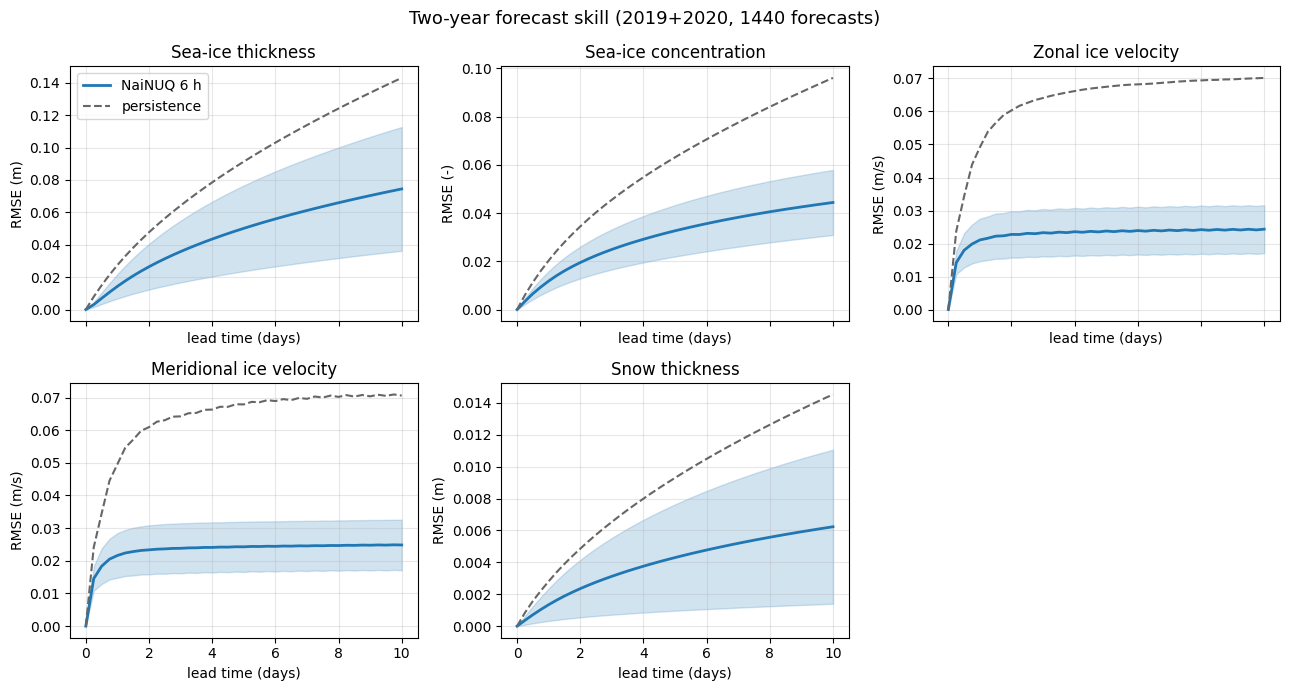

In [8]:
LABELS = {"sit": "Sea-ice thickness", "sic": "Sea-ice concentration", "siu": "Zonal ice velocity",
          "siv": "Meridional ice velocity", "snt": "Snow thickness"}

fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharex=True)
for j, (v, ax) in enumerate(zip(VARIABLES, axes.flat)):
    m, s = fs[:, :, j].mean(0), fs[:, :, j].std(0)
    mp = fs_pers[:, :, j].mean(0)
    ax.plot(lead_days, m, color="C0", lw=2, label="NaiNUQ 6 h")
    ax.fill_between(lead_days, m - s, m + s, color="C0", alpha=0.2)
    ax.plot(lead_days, mp, color="0.4", ls="--", lw=1.5, label="persistence")
    ax.set_title(LABELS[v]); ax.set_ylabel(f"RMSE ({UNITS[v]})"); ax.grid(alpha=0.3)
    ax.set_xlabel("lead time (days)")
axes.flat[0].legend()
for ax in list(axes.flat)[len(VARIABLES):]:
    ax.axis("off")
fig.suptitle(f"Two-year forecast skill (2019+2020, {N_CYCLE} forecasts)", fontsize=13)
fig.tight_layout()
plt.show()


## Notes

- **Timing.** The reported NN inference time is the *pure* model forward pass cost. The full
  forecast cycle adds normalisation, post-processing and mask operations, so the end-to-end time per
  cycle is larger (see the printed statistics).
- **Memory.** Data is streamed: only the current `steps_per_cycle` window is held in RAM, so this
  notebook runs the full two-year forecast on a laptop with 16 GB RAM.
- **Identical numbers to `run_local.py`.** The same `Test.apply_emulator` is called on the same
  sliding windows, so the RMSE / bias are computed exactly as in the headless script.
- **Reproducing the paper statistics.** The paper figures take the step index 40 (10 days). `fs`
  above has the layout `(forecasts, lead steps, variables)`, so index `fs[:, 40, j]` is the 10-day RMSE.
